# Inverse Problem

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys, os
sys.path.insert(0, os.path.abspath("/Users/judykao/projects/func_GKB")) 

from fgkb.sampling import gen_quasi_mc_points

from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.io as pio

## plotting

In [2]:
def plot_compare_singular_values(Kappa, save_tag):
    plt.figure(figsize=(10,8))
    for kap in Kappa:
        S = Kappa[kap]["S"]
        # print(f"kappa={kap}, num_singular_values={len(S)}")
        plt.semilogy(range(1, len(S)+1), S, '-', linewidth=2.5, label=f'$\kappa={kap}, n={len(S)}$', marker='o', markersize=3)

    plt.xlabel('$j$')
    plt.ylabel('$\sigma_j$', rotation=0)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{save_tag}.png", dpi=300)
    # plt.show()

In [3]:
def compare_f_and_f_rec(f, f_reconstruct):
    residual = f - f_reconstruct
    mse = np.mean(np.abs(residual) ** 2)
    ss_res = np.sum(np.abs(residual) ** 2)
    ss_tot = np.sum(np.abs(f - np.mean(f)) ** 2)
    r2 = 1 - ss_res / ss_tot
    rel_l2 = np.sqrt(ss_res) / np.sqrt(np.sum(np.abs(f) ** 2))

    print(f"MSE          : {mse:.6e}")
    print(f"R²           : {r2:.6f}")
    print(f"Relative L2  : {rel_l2:.6e}")

In [4]:
from plotly.subplots import make_subplots

def plot_compare(theta, functions, labels=None):
    n_theta = 100
    n_phi = 200

    theta_grid = np.linspace(0, np.pi, n_theta)
    # phi_grid = np.linspace(0, 2*np.pi, n_phi, endpoint=False)
    phi_grid = np.linspace(0, 2*np.pi, n_phi + 1)

    Theta, Phi = np.meshgrid(theta_grid, phi_grid)

    X = np.sin(Theta) * np.cos(Phi)
    Y = np.sin(Theta) * np.sin(Phi)
    Z = np.cos(Theta)

    from scipy.interpolate import griddata

    raw_points = np.column_stack((theta[:, 0], theta[:, 1]))  # (N, 2): col0=theta, col1=phi

    # 週期性延伸：複製 phi-2π 和 phi+2π 兩份
    points_ext = np.vstack([
        raw_points,
        raw_points + [0,  2*np.pi],
        raw_points + [0, -2*np.pi],
    ])

    def interp(values):
        values_ext = np.tile(values, 3)  # 對應延伸
        return griddata(points_ext, values_ext, (Theta, Phi), method='linear')

    Y_grid_1 = interp(functions[0].real)
    Y_grid_2 = interp(functions[1].real)

    pio.renderers.default = "browser"

    if labels is None:
        labels = [f"f{i}" for i in range(len(functions))]

    fig = make_subplots(
        rows=1, cols=2,
        specs=[[{'is_3d': True}, {'is_3d': True}]],
        subplot_titles=[labels[0], labels[1]]
    )

    fig.add_trace(
        go.Surface(
            x=X, y=Y, z=Z,
            surfacecolor=Y_grid_1,
            colorscale='Viridis',
            colorbar=dict(title=labels[0], x=-0.07)
        ),
        1, 1
    )

    fig.add_trace(
        go.Surface(
            x=X, y=Y, z=Z,
            surfacecolor=Y_grid_2,
            colorscale='Viridis',
            colorbar=dict(title=labels[1])
        ),
        1, 2
    )

    fig.update_layout(title="Function on Unit Sphere")

    fig.show()

In [5]:

def plot_volume_3d(samples, f, f_rec=None, grid_size=30, method='linear'):
    from scipy.interpolate import griddata
    """
    samples: (N,3)
    f: (N,)
    f_rec: (N,) or None
    """

    pio.renderers.default = "browser"

    f = np.real(f)

    # --- 建立 grid ---
    lin = np.linspace(-1, 1, grid_size)
    X, Y, Z = np.meshgrid(lin, lin, lin)
    grid_points = np.vstack([X.ravel(), Y.ravel(), Z.ravel()]).T

    # --- interpolate f ---
    f_grid = griddata(samples, f, grid_points, method=method)
    f_grid = f_grid.reshape((grid_size, grid_size, grid_size))
    f_grid = np.nan_to_num(f_grid, nan=0.0)

    if f_rec is not None:
        f_rec = np.real(f_rec)

        f_rec_grid = griddata(samples, f_rec, grid_points, method=method)
        f_rec_grid = f_rec_grid.reshape((grid_size, grid_size, grid_size))
        f_rec_grid = np.nan_to_num(f_rec_grid, nan=0.0)

        cmin = min(f_grid.min(), f_rec_grid.min())
        cmax = max(f_grid.max(), f_rec_grid.max())

        fig = make_subplots(
            rows=1, cols=2,
            specs=[[{'type': 'scene'}, {'type': 'scene'}]],
            subplot_titles=("f(original)", "f(reconstructed)")
        )

        # --- f ---
        fig.add_trace(go.Volume(
            x=X.flatten(), y=Y.flatten(), z=Z.flatten(),
            value=f_grid.flatten(),
            isomin=cmin, isomax=cmax,
            opacity=0.1,
            surface_count=20,
            colorscale='Viridis',
            colorbar=dict(title='value')
        ), row=1, col=1)

        # --- f_rec ---
        fig.add_trace(go.Volume(
            x=X.flatten(), y=Y.flatten(), z=Z.flatten(),
            value=f_rec_grid.flatten(),
            isomin=cmin, isomax=cmax,
            opacity=0.1,
            surface_count=20,
            colorscale='Viridis',
            showscale=False
        ), row=1, col=2)

        # fig.update_layout(title="Volume: f vs f_rec")

    else:
        fig = go.Figure(data=go.Volume(
            x=X.flatten(), y=Y.flatten(), z=Z.flatten(),
            value=f_grid.flatten(),
            isomin=f_grid.min(),
            isomax=f_grid.max(),
            opacity=0.1,
            surface_count=15,
            colorscale='Viridis',
            colorbar=dict(title='f')
        ))

        fig.update_layout(title="Volume: f")

    # --- axis ---
    fig.update_layout(
        scene=dict(xaxis_title='y1', yaxis_title='y2', zaxis_title='y3'),
        scene2=dict(xaxis_title='y1', yaxis_title='y2', zaxis_title='y3')
    )

    fig.show()

## Herglotz function (n=2)

In [6]:
Kappa = {
    5: np.load("/Users/judykao/projects/func_GKB/results/example_Herglotz_n2_kap5/solution.npz"),
    10: np.load("/Users/judykao/projects/func_GKB/results/example_Herglotz_n2_kap10/solution.npz"),
    20: np.load("/Users/judykao/projects/func_GKB/results/example_Herglotz_n2_kap20/solution.npz"),
    30: np.load("/Users/judykao/projects/func_GKB/results/example_Herglotz_n2_kap30/solution.npz"),
    40: np.load("/Users/judykao/projects/func_GKB/results/example_Herglotz_n2_kap40/solution.npz")
}

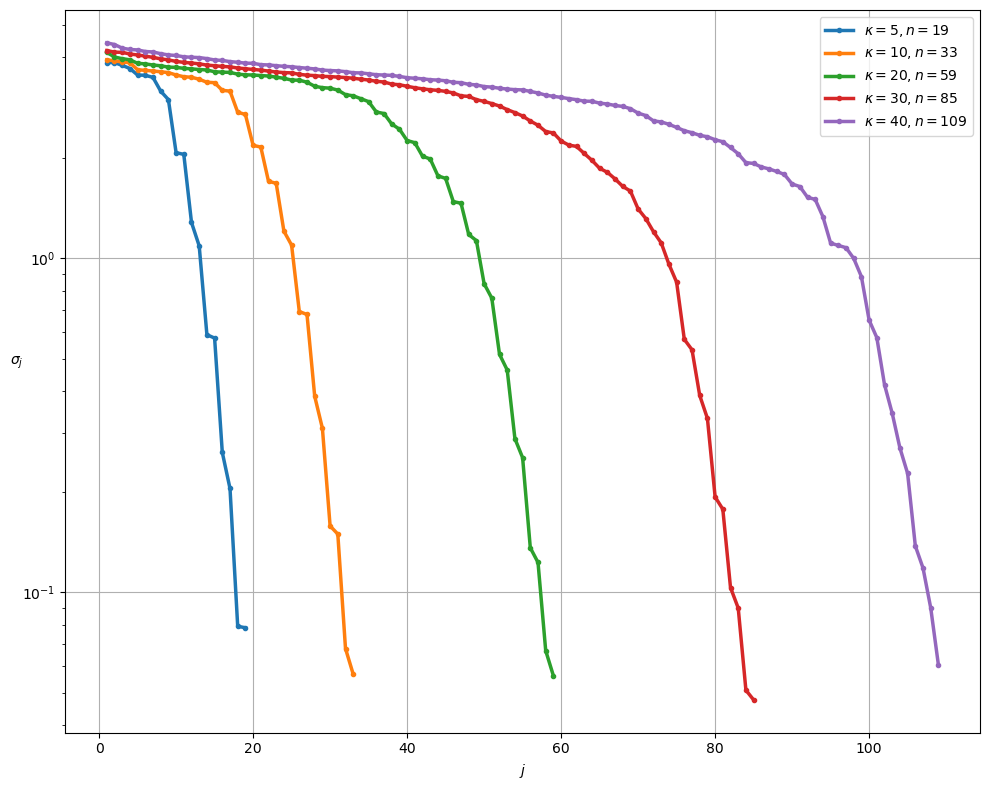

In [7]:
plot_compare_singular_values(Kappa, "Herglotz_n2")

### Examples

In [8]:
kap = 20
U, S, V = Kappa[kap]["U"], Kappa[kap]["S"], Kappa[kap]["V"]
N_theta = V[0].shape[0]
N_x = U[0].shape[0]

In [9]:
def inverse_transform(f, U, S, V, tag="Herglotz_n2"):
    theta = np.linspace(0, 2 * np.pi, N_theta, endpoint=False)
    w_theta = 2 * np.pi / N_theta
    print(f"theta.shape: {theta.shape}")

    x = gen_quasi_mc_points(2, N_x, [-1, -1], [1, 1])
    w_x = 4.0 / N_x
    print(f"x.shape: {x.shape}")

    cos_th = np.cos(theta)[None, :]
    sin_th = np.sin(theta)[None, :]
    x1, x2 = (x[:, i][:, None] for i in range(2))

    E = np.exp(1j * kap * (x1 * cos_th + x2 * sin_th))
    print(f"E.shape: {E.shape}")               

    T=lambda f: np.sqrt(kap) * E.dot(f * w_theta)
    inner_cod=lambda u, v: np.sum(np.conjugate(u) * v) * w_x
    g = T(f)

    g_proj = np.zeros(N_x, dtype=complex)
    coeff = []
    for i, u in enumerate(U):
        c = inner_cod(u, g)
        coeff.append(c)
        g_proj += c * u

    f_reconstruct = np.zeros_like(f, dtype=complex)
    for i, v in enumerate(V):
        f_reconstruct += (coeff[i] / S[i]) * v

    plt.figure()
    plt.plot(np.real(f), label='f (original)')
    plt.plot(np.real(f_reconstruct), label='f (reconstructed)')
    plt.xlabel('$N_\\theta$')
    plt.ylabel('f', rotation=0)
    plt.legend(loc='upper right')
    plt.savefig(f'{tag}.png', dpi=300)
    plt.show()

    compare_f_and_f_rec(f, f_reconstruct)

theta.shape: (360,)
x.shape: (1000, 2)
E.shape: (1000, 360)


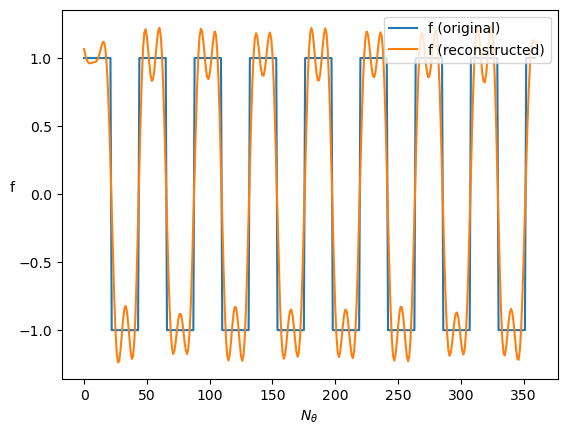

MSE          : 9.538071e-02
R²           : 0.904572
Relative L2  : 3.088377e-01


In [10]:
f1 = np.zeros(N_theta, dtype=complex)
i = 0
end = 0
angle = 22
while end < 360:
    start = angle * i 
    end = angle * (i+1)
    if i % 2 == 0:
        f1[start:end] = 1
    else:
        f1[start:end] = -1
    i += 1

inverse_transform(f1, U, S, V, tag="Herglotz_n2_f1")

theta.shape: (360,)
x.shape: (1000, 2)
E.shape: (1000, 360)


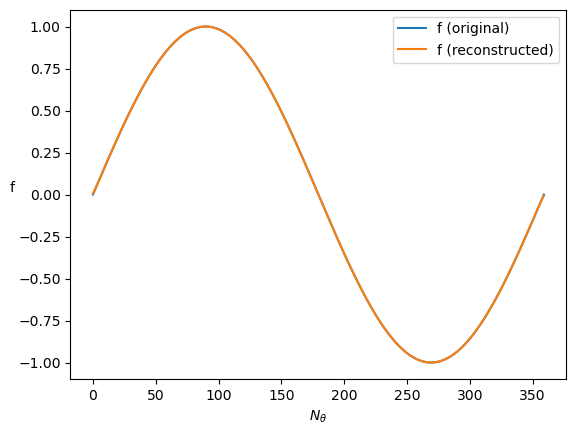

MSE          : 5.568240e-07
R²           : 0.999999
Relative L2  : 1.056764e-03


In [11]:
f2 = np.sin(np.linspace(0, 2*np.pi, N_theta))

inverse_transform(f2, U, S, V, tag="Herglotz_n2_f2")

theta.shape: (360,)
x.shape: (1000, 2)
E.shape: (1000, 360)


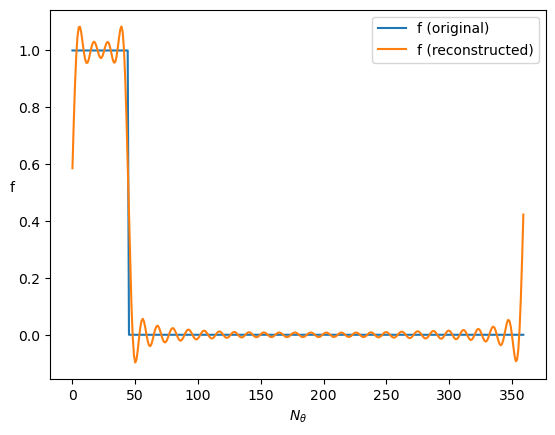

MSE          : 3.230880e-03
R²           : 0.970461
Relative L2  : 1.607701e-01


In [12]:
f3 = np.zeros(N_theta, dtype=complex)
f3[:45] = 1

inverse_transform(f3, U, S, V, tag="Herglotz_n2_f3")

In [13]:
# f = V[1]
# inverse_transform(f, U, S, V, tag="Herglotz_n2_v1")

## Herglotz function (n=3)

In [14]:
Kappa = {
    5: np.load("/Users/judykao/projects/func_GKB/results/example_Herglotz_n3_kap5/solution.npz"),
    10: np.load("/Users/judykao/projects/func_GKB/results/example_Herglotz_n3_kap10/solution.npz"),
    20: np.load("/Users/judykao/projects/func_GKB/results/example_Herglotz_n3_kap20/solution.npz")
}

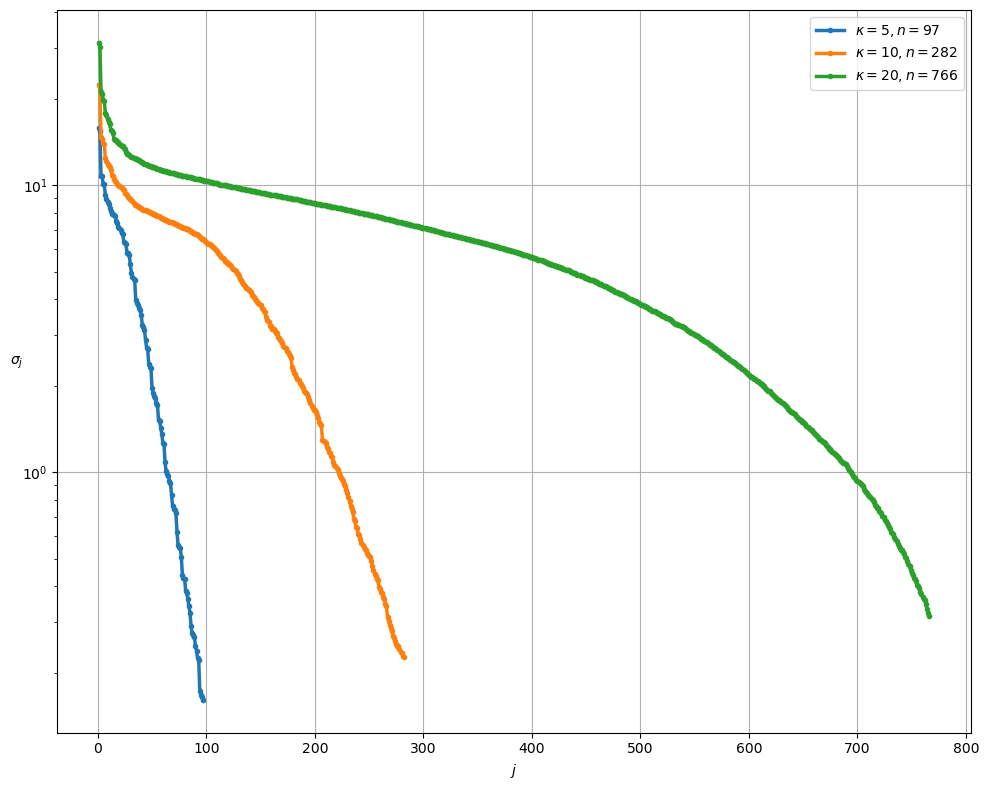

In [15]:
plot_compare_singular_values(Kappa, "Herglotz_n3")

### Examples

In [16]:
kap = 10
U, S, V = Kappa[kap]["U"], Kappa[kap]["S"], Kappa[kap]["V"]
N_theta = V[0].shape[0]
N_x = U[0].shape[0]

In [17]:
def inverse_transform(f, U, S, V, tag="Herglotz_n2"):
    theta = gen_quasi_mc_points(2, N_theta, [0, 0], [np.pi, 2 * np.pi])
    w_theta = 4 * np.pi / N_theta
    print(f"theta.shape: {theta.shape}")
    
    x = gen_quasi_mc_points(3, N_x, [-1, -1, -1], [1, 1, 1])
    w_x = 8.0 / N_x
    print(f"x.shape: {x.shape}")

    cos_phi = np.cos(theta[:, 0])[None, :]
    sin_phi = np.sin(theta[:, 0])[None, :]
    cos_th = np.cos(theta[:, 1])[None, :]
    sin_th = np.sin(theta[:, 1])[None, :]
    x1, x2, x3 = (x[:, i][:, None] for i in range(3))

    E = np.exp(1j * kap * (x1 * (sin_phi * cos_th) + x2 * (sin_phi * sin_th) + x3 * cos_phi))

    T=lambda f: kap * E.dot(f * w_theta)
    # inner_dom=lambda u, v: np.sum(np.conjugate(u) * v) * w_theta,
    inner_cod=lambda u, v: np.sum(np.conjugate(u) * v) * w_x
    g = T(f)

    coeff = []
    for i, u in enumerate(U):
        c = inner_cod(u, g)
        coeff.append(c)

    f_reconstruct = np.zeros_like(f, dtype=complex)
    for i, v in enumerate(V):
        f_reconstruct += (coeff[i] / S[i]) * v

    plot_compare(theta, [f, f_reconstruct], labels=['original', 'reconstruct'])
    compare_f_and_f_rec(f, f_reconstruct)

In [18]:
theta = gen_quasi_mc_points(2, N_theta, [0, 0], [np.pi, 2 * np.pi])
x_theta, y_theta = theta[:, 0], theta[:, 1]
f1 = np.where((x_theta < np.pi/2) & (y_theta < np.pi), 1, 0)

inverse_transform(f1, U, S, V, tag="Herglotz_n3_f1")

theta.shape: (1000, 2)
x.shape: (5000, 3)
MSE          : 1.223336e-02
R²           : 0.934929
Relative L2  : 2.207679e-01


In [19]:
f2 = np.sin(kap*x_theta)
inverse_transform(f2, U, S, V, tag="Herglotz_n3_f2")

theta.shape: (1000, 2)
x.shape: (5000, 3)
MSE          : 4.600856e-03
R²           : 0.990799
Relative L2  : 9.592070e-02


In [20]:
f3 = np.sin(x_theta+y_theta)
inverse_transform(f3, U, S, V, tag="Herglotz_n3_f3")

theta.shape: (1000, 2)
x.shape: (5000, 3)
MSE          : 1.216812e-02
R²           : 0.975693
Relative L2  : 1.559083e-01


In [21]:
# f = V[1]
# inverse_transform(f, U, S, V, tag="Herglotz_n3_v1")

## Multifreq Inverse Source

In [22]:
MaxKappa = {
    5: np.load("/Users/judykao/projects/func_GKB/results/example_multifreq_inverse_source_MaxKap5/solution.npz"),
    10: np.load("/Users/judykao/projects/func_GKB/results/example_multifreq_inverse_source_MaxKap10/solution.npz"),
    15: np.load("/Users/judykao/projects/func_GKB/results/example_multifreq_inverse_source_MaxKap15/solution.npz"),
    20: np.load("/Users/judykao/projects/func_GKB/results/example_multifreq_inverse_source_MaxKap20/solution.npz")
}

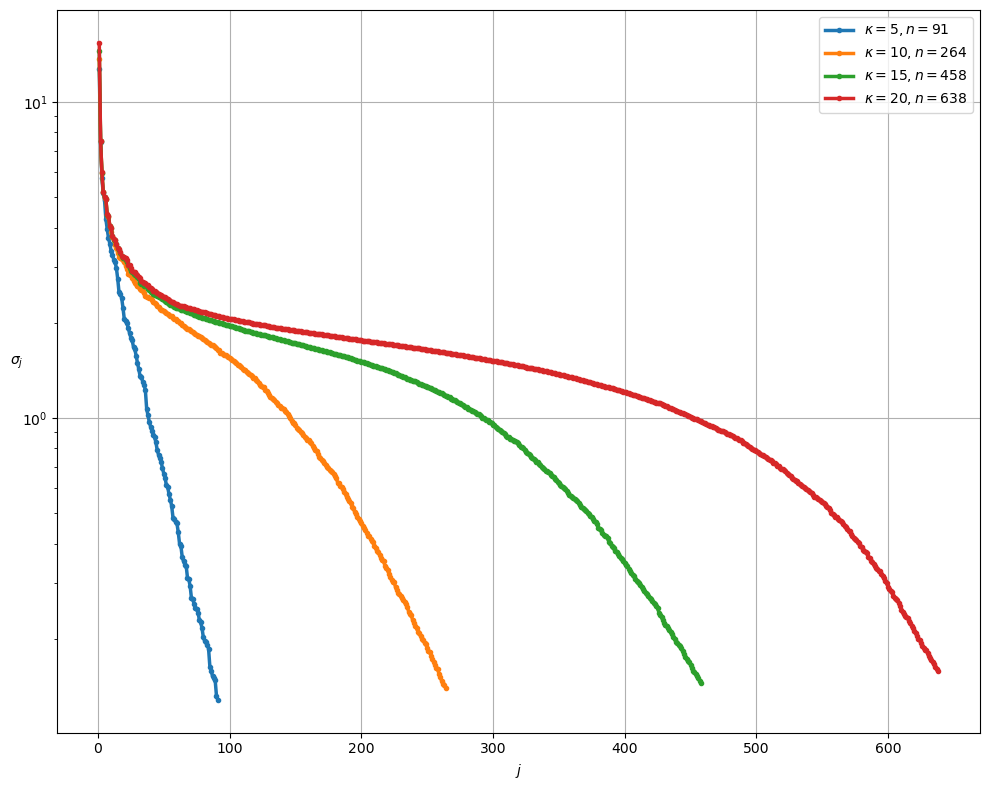

In [23]:
plot_compare_singular_values(MaxKappa, "multifreq_inverse_source")

## Examples

In [24]:
k_max = 10
U, S, V = MaxKappa[k_max]["U"], MaxKappa[k_max]["S"], MaxKappa[k_max]["V"]

N_kappa = 10
N_x_hat = 100
N_ball = 5000

In [25]:
def inverse_transform(f, U, S, V, tag="Herglotz_n2"):
    ball = gen_quasi_mc_points(3, N_ball, [-1, -1, -1], [1, 1, 1])
    w_B = 8.0 / N_ball

    kappa = np.linspace(0, k_max, N_kappa)
    w_kappa = k_max / N_kappa

    x_hat = gen_quasi_mc_points(2, N_x_hat, [0, 0], [np.pi, 2 * np.pi])
    w_x_hat = 4 * np.pi / N_x_hat

    sp, cp = np.sin(x_hat[:, 0])[None, :], np.cos(x_hat[:, 0])[None, :]
    st, ct = np.sin(x_hat[:, 1])[None, :], np.cos(x_hat[:, 1])[None, :]
    b1, b2, b3 = (ball[:, i][:, None] for i in range(3))

    rows = [np.exp(1j * kap * (b1 * sp * ct + b2 * sp * st + b3 * cp)).T for kap in kappa]
    E = np.vstack(rows)

    T=lambda f: E.conj() @ (f * w_B)
    inner_cod=lambda u, v: np.sum(np.conjugate(u) * v) * w_kappa * w_x_hat
    g = T(f)

    coeff = []
    for i, u in enumerate(U):
        c = inner_cod(u, g)
        coeff.append(c)

    f_reconstruct = np.zeros_like(f, dtype=complex)
    for i, v in enumerate(V):
        f_reconstruct += (coeff[i] / S[i]) * v

    plot_volume_3d(ball, f, f_reconstruct)
    compare_f_and_f_rec(f, f_reconstruct)

In [26]:
def make_f_grid(y_samples):
    f = np.zeros(len(y_samples), dtype=complex)
    
    for idx, y in enumerate(y_samples):
        ix = int((y[0] + 1) / (2/3))  # 0, 1, 2
        iy = int((y[1] + 1) / (2/3))  # 0, 1, 2
        iz = int((y[2] + 1) / (2/3))  # 0, 1, 2

        ix = min(ix, 2)
        iy = min(iy, 2)
        iz = min(iz, 2)

        if (ix + iy + iz) % 2 == 0:
            f[idx] = 1.0
        else:
            f[idx] = 0.0
    
    return f

ball = gen_quasi_mc_points(3, N_ball, [-1, -1, -1], [1, 1, 1])
f1 = make_f_grid(ball)
inverse_transform(f1, U, S, V, tag="multifreq_inverse_source_f1")

MSE          : 9.680590e-02
R²           : 0.612251
Relative L2  : 4.321340e-01


In [27]:
y1_col = ball[:, 0]
y2_col = ball[:, 1]
y3_col = ball[:, 2]
l=0.5
f2 = np.where((y3_col > -l) & (y3_col < l) & (y2_col > -l) & (y2_col < l) & (y1_col > -l) & (y1_col < l), 1, 0)
inverse_transform(f2, U, S, V, tag="multifreq_inverse_source_f2")

MSE          : 2.105912e-02
R²           : 0.806930
Relative L2  : 4.111129e-01


In [28]:
y1_col = ball[:, 0]
y2_col = ball[:, 1]
y3_col = ball[:, 2]
l = 0.5
f3 = np.where(y1_col**2 + y2_col**2 + y3_col**2 < l**2, 1, 0)
inverse_transform(f3, U, S, V, tag="multifreq_inverse_source_f3")

MSE          : 1.179526e-02
R²           : 0.806473
Relative L2  : 4.253339e-01


In [29]:
# f = V[1]
# inverse_transform(f, U, S, V, tag="multifreq_inverse_source_f")